# Introduction to Machine Learning

**Agenda**

1. What is machine learning: learning from examples, what ML needs, how it differs from the algorithms so far
2. Types of machine learning: supervised (regression and classification), unsupervised
3. Data: features, labels, preprocessing
4. How a model learns: learnable parameters, the loss, gradient descent, hyperparameters
5. Linear regression - a model for **regression**
6. Does the model generalize? Train / validation / test, underfitting and overfitting, the bias-variance tradeoff,
   cross-validation
7. Logistic regression - linear regression extended to **classification**
8. Summary

## Setup: imports and helper code

The helpers generate the toy datasets, draw the diagrams (the data splits, the k folds, the decision boundaries), and
contain the polynomial fits of section 6.2 and the logistic regression training of section 7.3, so that those sections
show only the pictures. You do not need to understand the helper code.

In [1]:
# The imports used in the rest of the notebook
import matplotlib.pyplot as plt
import numpy as np
from numpy.polynomial import Polynomial

In [2]:
# Helper code that can be skipped

def make_houses(n, rng):
    # house size in m² and price in thousands of €: price ≈ 1.5 · size + 40, plus noise
    size = rng.uniform(40, 160, n)
    price = 1.5 * size + 40 + rng.normal(0, 20, n)
    return size, price


def true_curve(x):
    # the hidden "truth" behind the data in section 6
    return np.sin(2 * np.pi * x)


def make_wave(n, rng, noise=0.25):
    x = rng.uniform(0, 1, n)
    return x, true_curve(x) + rng.normal(0, noise, n)


def make_wave_split():
    rng = np.random.default_rng(1)
    wave_x_train, wave_y_train = make_wave(15, rng)
    wave_x_val, wave_y_val = make_wave(30, rng)
    return wave_x_train, wave_y_train, wave_x_val, wave_y_val


def draw_degree_fits(x_train, y_train, x_val, y_val):
    grid = np.linspace(0, 1, 300)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
    for ax, degree, verdict in zip(axes, (1, 4, 12), ("underfitting", "a good fit", "overfitting")):
        model = Polynomial.fit(x_train, y_train, degree)                  # linear regression on x, x², ..., x^d
        train_error = np.mean((y_train - model(x_train)) ** 2)
        val_error = np.mean((y_val - model(x_val)) ** 2)
        ax.plot(grid, true_curve(grid), color="gray", lw=1, label="the truth")
        ax.plot(grid, model(grid), color="#c62828", lw=2, label=f"degree {degree}")
        ax.scatter(x_train, y_train, color="#4f81bd", zorder=3, label="training points")
        ax.scatter(x_val, y_val, color="#f79646", s=12, zorder=3, label="validation points")
        ax.set_title(f"{verdict}\ntrain MSE {train_error:.3f}, validation MSE {val_error:.3f}")
        ax.set_ylim(-2, 2)
    axes[0].legend(loc="lower left", fontsize=8)
    fig.tight_layout()
    plt.close(fig)
    return fig


def make_two_groups(n, rng):
    # two overlapping clouds of points in 2D, labelled 0 and 1
    group0 = rng.normal([2.0, 2.0], 1.1, size=(n, 2))
    group1 = rng.normal([4.5, 4.0], 1.1, size=(n, 2))
    return np.vstack([group0, group1]), np.r_[np.zeros(n), np.ones(n)]


def draw_bar(ax, parts, y, title=""):
    # one horizontal bar split into labelled, coloured parts: [(label, fraction, colour), ...]
    left = 0
    for label, fraction, colour in parts:
        ax.barh(y, fraction, left=left, color=colour, edgecolor="white", height=0.6)
        ax.text(left + fraction / 2, y, label, ha="center", va="center", color="white", fontweight="bold", fontsize=9)
        left += fraction
    ax.text(-0.02, y, title, ha="right", va="center", fontsize=11)


def draw_k_fold(ax, k=5):
    for fold in range(k):
        parts = [("validation" if i == fold else "train", 1 / k, "#f79646" if i == fold else "#4f81bd")
                 for i in range(k)]
        draw_bar(ax, parts, -fold, title=f"round {fold + 1}")
    ax.set_xlim(-0.25, 1.02)
    ax.set_ylim(-k + 0.4, 0.6)
    ax.axis("off")


def draw_classes(ax, X, y):
    ax.scatter(*X[y == 0].T, c="#c62828", marker="o", label="class 0", edgecolors="white")
    ax.scatter(*X[y == 1].T, c="#1f4e79", marker="s", label="class 1", edgecolors="white")


def draw_probabilities(ax, predict_probability, X, y, title="", range_X=None):
    # the background colour is the predicted probability of class 1; the black line is where it is 0.5
    range_X = X if range_X is None else range_X                 # the area to draw, so panels can share it
    x1, x2 = np.meshgrid(np.linspace(range_X[:, 0].min() - 1, range_X[:, 0].max() + 1, 200),
                         np.linspace(range_X[:, 1].min() - 1, range_X[:, 1].max() + 1, 200))
    p = predict_probability(np.c_[x1.ravel(), x2.ravel()]).reshape(x1.shape)
    shade = ax.contourf(x1, x2, p, levels=np.linspace(0, 1, 11), cmap="RdBu", alpha=0.35)
    ax.contour(x1, x2, p, levels=[0.5], colors="black", linewidths=2)
    ax.set_xlim(x1.min(), x1.max())
    ax.set_ylim(x2.min(), x2.max())
    draw_classes(ax, X, y)
    ax.set_title(title)
    return shade


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def cross_entropy(y_true, y_prob, eps=1e-8):
    y_prob = np.clip(y_prob, eps, 1 - eps)                     # avoid log(0)
    return -np.mean(y_true * np.log(y_prob) + (1 - y_true) * np.log(1 - y_prob))


def logistic_regression(X, y, learning_rate=0.5, n_iters=2000):
    weights, bias = np.zeros(X.shape[1]), 0.0                 # 1. initialize
    losses = []
    for _ in range(n_iters):
        y_prob = sigmoid(X @ weights + bias)                  # 2. predict: linear part, then the sigmoid
        losses.append(cross_entropy(y, y_prob))               # 3. measure the loss
        error = y - y_prob
        weights = weights + learning_rate * X.T @ error / len(y)   # 4. update - the same rule as before
        bias = bias + learning_rate * np.mean(error)
    return weights, bias, losses


def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)


def draw_logistic_regression():
    rng = np.random.default_rng(3)
    X, y = make_two_groups(40, rng)
    order = rng.permutation(len(y))
    train, test = order[:60], order[60:]                       # 75% training, 25% test
    mean, std = X[train].mean(axis=0), X[train].std(axis=0)
    X_train, y_train = (X[train] - mean) / std, y[train]
    X_test, y_test = (X[test] - mean) / std, y[test]

    weights, bias, losses = logistic_regression(X_train, y_train)


    def predict_probability(X):
        return sigmoid(X @ weights + bias)


    print(f"weights: {weights.round(2)}, bias: {bias:.2f}")
    print(f"cross-entropy: {losses[0]:.3f} at the start -> {losses[-1]:.3f} after training")
    print(f"train accuracy: {accuracy(y_train, predict_probability(X_train) > 0.5):.0%}")
    print(f"test accuracy:  {accuracy(y_test, predict_probability(X_test) > 0.5):.0%}")

    fig = plt.figure(figsize=(16, 4.2), layout="constrained")
    grid = fig.add_gridspec(1, 4, width_ratios=[1, 1, 0.05, 1])
    left, middle, colour_bar_axes, right = (fig.add_subplot(grid[0, column]) for column in range(4))
    range_X = np.vstack([X_train, X_test])
    shade = draw_probabilities(left, predict_probability, X_train, y_train, "training set", range_X)
    draw_probabilities(middle, predict_probability, X_test, y_test, "test set (never seen in training)", range_X)
    fig.colorbar(shade, cax=colour_bar_axes).ax.set_title("probability\nof class 1", fontsize=9)
    left.legend(loc="upper left")
    right.plot(losses, color="#c62828")
    right.set_xlabel("iteration")
    right.set_ylabel("cross-entropy")
    right.set_title("The loss curve")
    plt.close(fig)
    return fig

---

# 1. What is machine learning?

## 1.1 Learning instead of programming

**Machine Learning uses data to make computers do things, that are not purely rule based like in standard algorithms.**

In all the lectures so far, **we** wrote down how to solve the problem:

- in search we wrote the successor function, the goal test and the heuristic,
- in CSPs we wrote the constraints,
- in genetic algorithms we wrote the fitness function,
- in games we wrote the evaluation function - remember $Eval(s) = 9 \cdot (\text{queens}) + 5 \cdot
  (\text{rooks}) + \dots$, where a person chose the weights 9, 5, 3, 1.

Some problems are hard to describe with rules. Try writing the rules that tell a cat from a dog in a photo, or a spam
email from a normal one. It is much easier to collect **examples** - photos labelled "cat" or "dog", emails labelled
"spam" or "not spam" - and let the computer **find the rule itself**.

## 1.2 How do we learn?

- **Deductive learning**: general rule → specific examples. "All dogs bark; Rex is a dog ⇒ Rex barks."
- **Inductive learning**: specific examples → general rule. "Every dog I have seen barks ⇒ dogs bark."

**Machine learning is inductive learning.** For example, if we have seen enough examples of pictures of dogs (training data), we can tell whether a given picture is a picture of a dog or not, even if this picture has never been seen before. **Nobody gave the computer a definition
of a dog. It learned it purely from the training data.**

The goal is **not** to remember the examples, but to **generalize** - to give correct answers for **new** examples that
were not in the training data. This is the most important idea of the whole lecture.

## 1.3 What does machine learning need?

| Ingredient | What it is | Example: predicting house prices |
|---|---|---|
| **Data** | many examples, as representative of the real world as possible | 1,000 houses that were sold |
| **Features** (inputs, $x$) | the measurable properties of an example | size, number of rooms, year built |
| **Labels** (targets, $y$) | the correct answers - only in supervised learning | the price each house was sold for |
| **A model** | a function $\hat{y} = f(x)$ with adjustable numbers (**parameters**) | $\hat{y}$ = $w \cdot$ size + $b$, where $\hat{y}$ is the predicted price |
| **A loss function** | a number that measures how wrong the model's predictions are | the average squared error of the predicted price $\hat{y}$ and the real price $y$ in €, e.g. $(\hat{y}-y)^2$ |
| **An optimizer** | a method that changes the parameters to make the loss smaller | gradient descent, which we will see later |
| **Evaluation on new data** | a check on examples the model has **not** seen | houses that were not used for training |

## 1.4 Machine learning vs the algorithms so far

| | Search, CSP, games | Machine learning |
|---|---|---|
| **We give the computer** | the rules of the problem (successors, constraints, a heuristic) | examples (data) |
| **The result** | a solution of **one** problem: a path, an assignment, a move | a **model** - a function that answers **new** questions |
| **Knowledge comes from** | the programmer | the data |
| **When it is used** | the rules are known and exact (chess, a timetable, a map) | the rules are unknown or too complex (images, speech, spam) |

ML is still search and optimization underneath - it searches for the best **parameters** of a model. Gradient descent is a kind of **local search**, like hill climbing - from the current parameters, take a step (change the parameters a little bit) in the direction that improves the loss most. Basically, **we update the parameters iteratively, such that the loss function becomes smaller.** This is called **learning**.

---

# 2. Types of machine learning

## 2.1 Supervised learning

The training data has **inputs $x$ and the correct outputs $y$** (labels) - "learn from data labelled with the right
answers". The model learns the mapping $x \to y$.

| Input $x$ | Output $y$ | Application |
|---|---|---|
| email | spam? (0 / 1) | spam filtering |
| audio | text transcript | speech recognition |
| English text | Spanish text | machine translation |
| ad, user info | click? (0 / 1) | online advertising |
| image of a phone | defect? (0 / 1) | visual inspection |

Supervised learning has two kinds of tasks, depending on **what $y$ is**:

| | **Regression** | **Classification** |
|---|---|---|
| **Output** | a continuous **number** - "how much?" | a **category** from a small set - "which one?" |
| **Example outputs** | 42.5, 101.3, 15.7 | yes / no; cat / dog / bird |
| **Examples** | house price, temperature, a person's age, sales next month, salary from experience | spam or not, disease positive or negative, cat or dog, will the customer leave, credit card fraud |
| **Measuring the error** | how far the prediction is from the truth: mean squared error (MSE), RMSE | how often the class is wrong: accuracy, precision, recall |
| **Algorithms** | **linear regression**, polynomial regression, random forest regression | **logistic regression**, decision trees, random forests, SVM, k-nearest neighbours |

> Do not let the name confuse you: **logistic regression is a classification algorithm**. Later we explain why it still has "regression" in its name.

The same data can lead to either task. A table of past days:

| Humidity | Wind | Temperature | Play tennis? |
|---|---|---|---|
| high | mid | 35° | No |
| mid | strong | 5° | No |
| mid | weak | 20° | Yes |
| high | weak | 25° | Yes |
| low | strong | 18° | No |

- Predict **"play tennis?"** for a new day (low, weak, 21°) → **classification** (the answer is Yes or No).
- Predict the **temperature** from the humidity and the wind → **regression** (the answer is a number).

## 2.2 Unsupervised learning

The data has **only inputs, no labels**. We want to find something interesting in unlabelled data. The most common task is **clustering** - grouping similar examples together, e.g. customers with similar shopping habits. Nobody tells the algorithm what the groups are or how many there are, the algorithm finds the structure itself.

## 2.3 Layering of AI methods

Deep Learning is Machine Learning with large **neural networks** with many layers. Most modern complex models like ChatGPT or Claude are Deep Learning based.

**AI ⊃ ML ⊃ neural networks ⊃ deep learning**: machine learning is one part of AI (search, CSPs and games are AI, but
not ML), neural networks are one kind of ML model, and deep learning uses deep (many-layer) neural networks.

The three main kinds side by side:

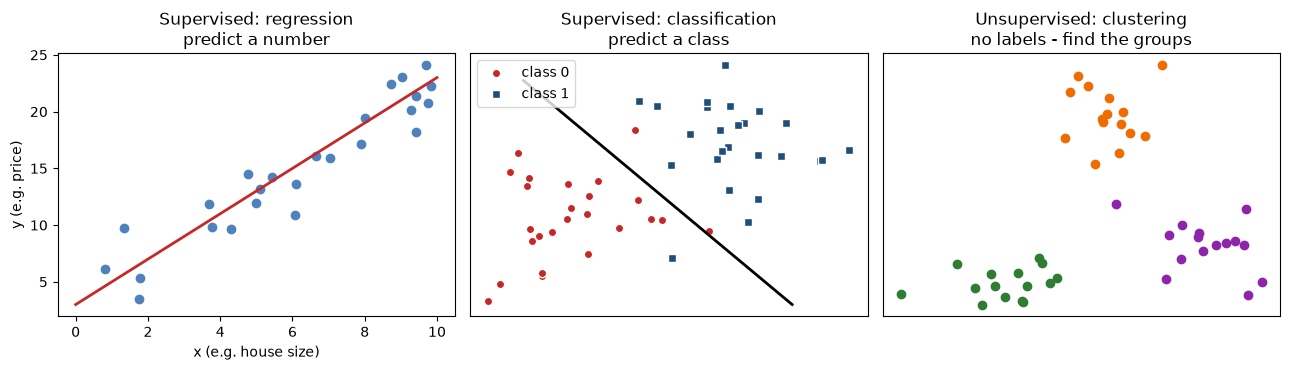

In [3]:
_rng = np.random.default_rng(4)
_fig, (_reg, _cls, _clu) = plt.subplots(1, 3, figsize=(13, 3.8))

_x = _rng.uniform(0, 10, 25)
_y = 2 * _x + 3 + _rng.normal(0, 2, 25)
_reg.scatter(_x, _y, color="#4f81bd")
_reg.plot([0, 10], [3, 23], color="#c62828", lw=2)
_reg.set_title("Supervised: regression\npredict a number")
_reg.set_xlabel("x (e.g. house size)")
_reg.set_ylabel("y (e.g. price)")

_X, _labels = make_two_groups(25, _rng)
draw_classes(_cls, _X, _labels)
_cls.plot([0.8, 5.8], [6.06, -0.19], color="black", lw=2)      # a line between the two groups
_cls.set_title("Supervised: classification\npredict a class")
_cls.legend(loc="upper left")

for _centre, _colour in (([1, 1], "#2e7d32"), ([5, 2], "#8e24aa"), ([3, 5], "#ef6c00")):
    _cluster = _rng.normal(_centre, 0.6, size=(15, 2))
    _clu.scatter(*_cluster.T, color=_colour)
_clu.set_title("Unsupervised: clustering\nno labels - find the groups")

for _ax in (_cls, _clu):
    _ax.set_xticks([])
    _ax.set_yticks([])
_fig.tight_layout()
plt.show()

In the middle and right plots the points look similar - the difference is that in the middle **we know** each point's class (the colour), and the model learns to separate them. On the right the colours are what the algorithm **finds**.

---

# 3. Data

## 3.1 Features and labels

A dataset is a table that contains:
- one **row** per example
- one **column** per **feature** - **A feature is a concrete characteristic of the example**
- **In supervised learning only** we have one additional column with the **label**.

We write the features of example $j$ as a vector $x_j = (x_{j1}, \dots, x_{jn})$, and (in supervised learning only) its label as $y_j$.

Our dataset is a table with rows $x_1, \dots, x_m$ and their labels $y_1, \dots, y_m$.

The task in supervised learning: given a new $x_t = (x_{t1}, \dots, x_{tn})$, predict its label $y_t$.

## 3.2 Data preprocessing

A model can only be as good as its data. Real-world data is usually:

- **incomplete**: missing values (a house without a size)
- **noisy**: errors and outliers (an income of −100)
- **inconsistent**: impossible combinations (sex: male, pregnant: yes), the same thing written differently ("Sofia", "SOFIA", "Sofiya")

The most common preprocessing steps:

- **Data cleaning**: fill in the missing values (e.g. with the average of the column, or the most common value), remove
  or correct outliers and inconsistencies.
- **Normalization (scaling)**: bring all features to a similar range, so that a feature measured in thousands (income)
  does not dominate a feature measured in units (number of children):
    - min-max scaling to $[0, 1]$: $x' = \frac{x - \min}{\max - \min}$
    - standardization: $x' = \frac{x - \text{mean}}{\text{standard deviation}}$
- **Data reduction**: remove irrelevant features, or combine many features into a few.
- **Encoding**: models work with numbers, so categories have to be turned into numbers, e.g. wind = weak / mid / strong → 0 / 1 / 2.

---

# 4. How a model learns

## 4.1 Learnable parameters

A **model** is a formula with unknown parameters. E.g. "price = $w \cdot$ size + $b$". The numbers $w$ and $b$ are the **learnable parameters** (also called **weights**). The model does not know them in advance, it **learns** them from the data. Different values of $w$ and $b$ give different results. **Training** means finding the values that fit the data best.

Simple models have a few parameters, and large neural networks have billions of parameters, however the idea is the same.

## 4.2 The loss function

To find the best parameters we need a number that says **how bad** the current parameters are. This is called the **loss function**.

For regression, the usual loss is the **mean squared error (MSE)**. For every example, take the difference between the prediction $\hat{y}_j$ and the true value $y_j$, square it, and average over all $N$ examples:

$$MSE = \frac{1}{N} \sum_{j=1}^{N} (y_j - \hat{y}_j)^2$$

Squaring makes every error positive, and punishes big errors much more than small ones. A model is better, if it achieves a smaller MSE.

Now that we know what a loss function is, we can say that **training is finding the parameters with the smallest loss.**

## 4.3 Gradient descent

How do we find the minimum? Imagine standing on a hill in fog, trying to reach the lowest point of the valley. You feel the slope under your feet, and take a step **downhill**. Repeat until the ground is flat.

The slope is the **derivative** (for several parameters, the **gradient** - the vector of partial derivatives). It points
uphill, so we step in the opposite direction:

$$w \leftarrow w - \alpha \cdot \frac{\partial \, Loss}{\partial w}$$

$\alpha$ is the **learning rate** - the size of the step.

```
Let w be any point in the parameter space
while not converged:
    for w_i in w:
        w_i ← w_i − α · ∂Loss(w) / ∂w_i
```

Let us try it on a simple function, $f(x) = 3x^2 - 4x + 5$. Its derivative is $f'(x) = 6x - 4$, which is zero at
$x = \frac{2}{3}$ - the minimum, where $f(\frac{2}{3}) = \frac{11}{3} \approx 3.67$. We start at $x = -2$ and take 15
steps with three different learning rates:

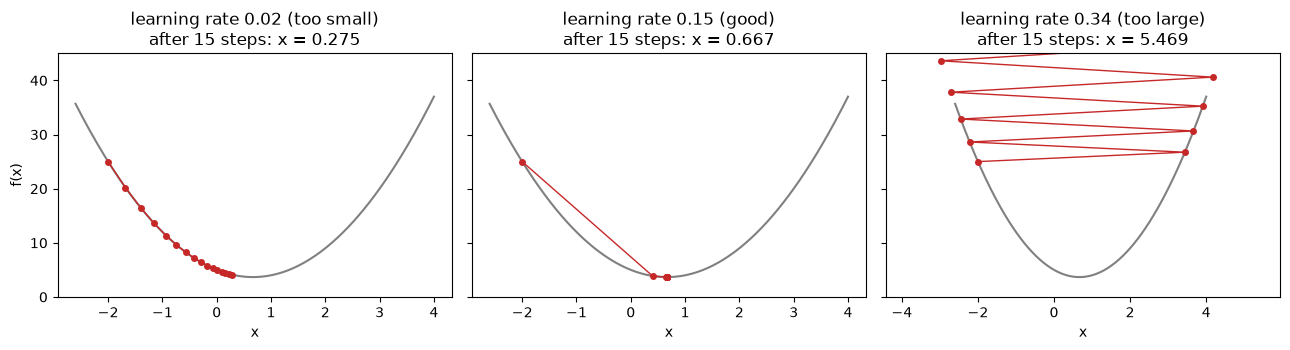

In [4]:
def f(x):
    return 3 * x**2 - 4 * x + 5


def f_derivative(x):
    return 6 * x - 4


_fig, _axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
_curve = np.linspace(-2.6, 4, 200)
for _ax, _rate, _verdict in zip(_axes, (0.02, 0.15, 0.34), ("too small", "good", "too large")):
    _x = -2.0
    _steps = [_x]
    for _ in range(15):
        _x = _x - _rate * f_derivative(_x)                   # one gradient descent step
        _steps.append(_x)
    _steps = np.array(_steps)
    _ax.plot(_curve, f(_curve), color="gray")
    _ax.plot(_steps, f(_steps), "o-", color="#c62828", markersize=4, lw=1)
    _ax.set_title(f"learning rate {_rate} ({_verdict})\nafter 15 steps: x = {_steps[-1]:.3f}")
    _ax.set_ylim(0, 45)
    _ax.set_xlabel("x")
_axes[0].set_ylabel("f(x)")
_fig.tight_layout()
plt.show()

- **Too small** (0.02): every step goes the right way, but it is still far from $\frac{2}{3}$ after 15 steps - training
  is slow.
- **Good** (0.15): reaches $x = 0.667$ in a few steps.
- **Too large** (0.34): it overshoots the minimum, jumps to the other side, overshoots again - further every time. The
  search **diverges**.

> Gradient descent finds a **local** minimum (which is not necessarily the **global** minimum), just like hill climbing finds a local maximum.

## 4.4 How a model trains

Every model in this course trains with the same loop:

1. **Initialize** the parameters (randomly, or with zeros).
2. **Predict**: compute the model's output for the training examples.
3. **Measure** the loss - how wrong the predictions are.
4. **Update**: compute the gradient of the loss and take a step downhill.
5. **Repeat** steps 2 - 4 (each repetition is an **iteration**, and one pass over all training data is an **epoch**) until the loss stops decreasing.

The **loss** should generally **go down** after every iteration.

## 4.5 Hyperparameters

Some numbers are **not** learned from the data - we have to choose them **before** training. They are called
**hyperparameters**:

| Learnable parameters | Hyperparameters |
|---|---|
| learned by the training algorithm | chosen by us, before training |
| e.g. the weights $w$, the bias $b$ | e.g. the learning rate $\alpha$, the number of iterations, ... |
| change at every training step | fixed during one training run |

How do we choose the hyperparameters? By trying several values and comparing how well the models do on data they have
not seen - that is what the **validation set** and **cross-validation** are for, which we will see later.

---

# 5. Linear regression

## 5.1 The model

The simplest model: a straight line. With one input $x$:

$$\hat{y} = h_w(x) = w_1 x + w_0$$

- $w_1$ is the **slope** (the **weight**): how much $\hat{y}$ changes when $x$ grows by 1
- $w_0$ is the **intercept** (the **bias**): the value of $\hat{y}$ when $x = 0$

Our example: N sold houses, their **size in m²** and their **price in thousands of €**. We want a line that predicts the price of a house from its size.

We know what the sell price of each house from the training set is, and this is what we are trying to predict for new houses. Since we have these prices, this is an example of **supervised** learning. The prices are called labels, and supervised learning means we will try to predict these labels. Since the prices (labels) are continuous values and not categorical, this is a **regression** problem.

## 5.2 The loss and its gradient

The loss is the MSE:

$$Loss(w_0, w_1) = \frac{1}{N} \sum_{j=1}^{N} (y_j - (w_1 x_j + w_0))^2$$

Its partial derivatives:

$$\frac{\partial Loss}{\partial w_0} = -\frac{2}{N} \sum_j (y_j - \hat{y}_j), \qquad
\frac{\partial Loss}{\partial w_1} = -\frac{2}{N} \sum_j (y_j - \hat{y}_j) \cdot x_j$$

Plugging them into the gradient descent step gives the update rule:

$$w_0 \leftarrow w_0 + \alpha \cdot \frac{2}{N}\sum_j (y_j - \hat{y}_j), \qquad
w_1 \leftarrow w_1 + \alpha \cdot \frac{2}{N}\sum_j (y_j - \hat{y}_j) \cdot x_j$$

In the code below, the constant 2 is absorbed into the learning rate $\alpha$, so the update uses $\frac{1}{N}$ instead of $\frac{2}{N}$.

Before training, we **scale** the size to $[0, 1]$ with min-max scaling, because the different scales of both weights could lead to different scales of their gradients, and one learning rate would be too large for one parameter and too small for the other.

In [5]:
house_size, house_price = make_houses(40, np.random.default_rng(0))   # generate synthetic data for houses
size_min, size_max = house_size.min(), house_size.max()
house_x = (house_size - size_min) / (size_max - size_min)             # min-max scaling to [0, 1]


def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


def linear_regression(x, y, learning_rate=0.5, n_iters=500):
    w1, w0 = 0.0, 0.0                                                 # 1. initialize
    history = []
    for _ in range(n_iters):
        y_pred = w1 * x + w0                                          # 2. predict
        history.append((w0, w1, mean_squared_error(y, y_pred)))       # 3. measure the loss
        w0 = w0 + learning_rate * np.mean(y - y_pred)                      # 4. update (the rule above)
        w1 = w1 + learning_rate * np.mean((y - y_pred) * x)
    return w0, w1, history


house_w0, house_w1, house_history = linear_regression(house_x, house_price)
print(f"learned parameters: w0 = {house_w0:.1f}, w1 = {house_w1:.1f}")
print(f"MSE: {house_history[0][2]:,.0f} at the start -> {house_history[-1][2]:,.0f} after training")

learned parameters: w0 = 101.5, w1 = 188.3
MSE: 44,762 at the start -> 461 after training


> IMPORTANT: These are the weights of the model using **SCALED** features. Since the data is synthetic (we generated it as $\text{price} = 1.5 \cdot \text{size} + 40 + \text{noise}$), for the **UNSCALED** features, $w_0$ would approximate 40, and $w_1$ would approximate 1.5.

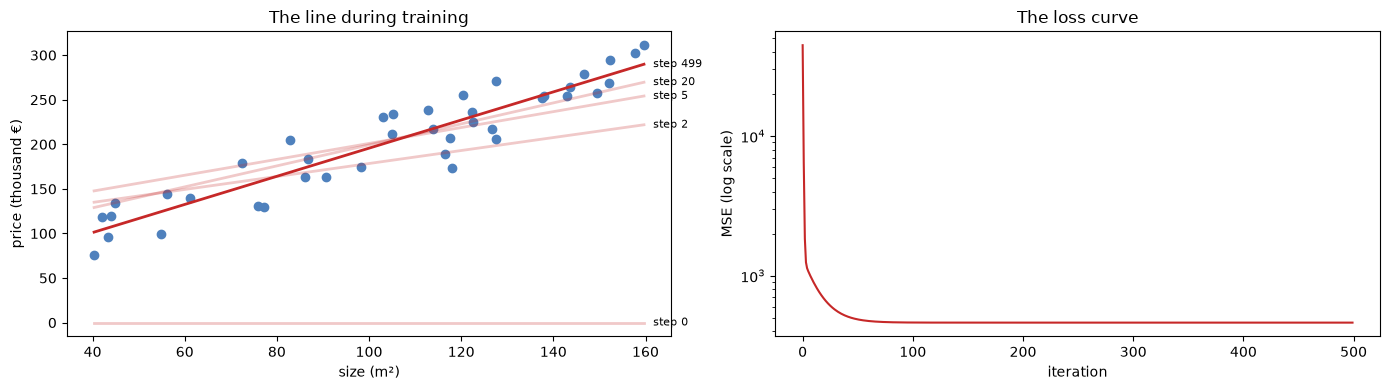

In [6]:
_fig, (_left, _right) = plt.subplots(1, 2, figsize=(14, 4))

_sizes = np.array([size_min, size_max])
_left.scatter(house_size, house_price, color="#4f81bd", zorder=2)
for _i in (0, 2, 5, 20, len(house_history) - 1):                         # the line at a few moments of training
    _w0, _w1, _ = house_history[_i]
    _left.plot(_sizes, _w1 * (_sizes - size_min) / (size_max - size_min) + _w0, color="#c62828",
               alpha=0.25 + 0.75 * (_i == len(house_history) - 1), lw=2)
    _left.text(_sizes[-1] + 2, _w1 + _w0, f"step {_i}", fontsize=8, va="center")
_left.set_xlabel("size (m²)")
_left.set_ylabel("price (thousand €)")
_left.set_title("The line during training")

_right.plot([loss for _, _, loss in house_history], color="#c62828")
_right.set_yscale("log")
_right.set_xlabel("iteration")
_right.set_ylabel("MSE (log scale)")
_right.set_title("The loss curve")
_fig.tight_layout()
plt.show()

- **Left**: the first line (step 0, all parameters 0) is flat at price 0. Every step moves it closer to the data.
- **Right**: the loss falls quickly at first, then flattens out - the model has converged.

Now the model can predict the price of a house it has never seen:

In [7]:
def predict_price(size):
    x = (size - size_min) / (size_max - size_min)       # scale the new input exactly like the training data
    return house_w1 * x + house_w0


for _size in (50, 100, 150):
    print(f"a house of {_size} m² -> predicted price {predict_price(_size):.0f} thousand €")

a house of 50 m² -> predicted price 117 thousand €
a house of 100 m² -> predicted price 196 thousand €
a house of 150 m² -> predicted price 275 thousand €


## 5.3 More features

With $n$ features, the model is a weighted sum of all of them:

$$\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_n x_n$$

e.g. price = $w_0$ + $w_1 \cdot$ size + $w_2 \cdot$ rooms + $w_3 \cdot$ age. Training is exactly the same - every weight gets the update $w_i \leftarrow w_i + \alpha \cdot \frac{1}{N}\sum_j (y_j - \hat{y}_j) \cdot x_{ji}$.

---

# 6. Does the model generalize?

A model that is perfect on its training data can still be useless - it may have just **memorized** the examples. What
we care about is the error on **new** data. This section shows how to measure it, and what can go wrong.

## 6.1 Train, validation and test sets

Before training, we split the data into three parts:

- **Training set**: the model learns its parameters from it.
- **Validation set**: used to **choose the hyperparameters** and compare models. The model never trains on it.
- **Test set**: used **once**, at the very end, to estimate how well the final model will do on new data.

Why not choose the hyperparameters on the test set? Because then we would pick the model that happens to be best on the test set, effectively "leaking" information that is used for testing into our decisions. The test set must stay unseen until the end, like the questions of an exam.

Typically we would use a split that is 80% / 10% / 10% for train / validation / test. The split must be **random** (otherwise e.g. all the expensive houses could end up in the test set).

> Preprocessing must also respect the split. For example, if we do scaling, we should compute the min and max on the **training** set only. After that we will apply these numbers to the validation and test sets. Otherwise information from the test set leaks into training.

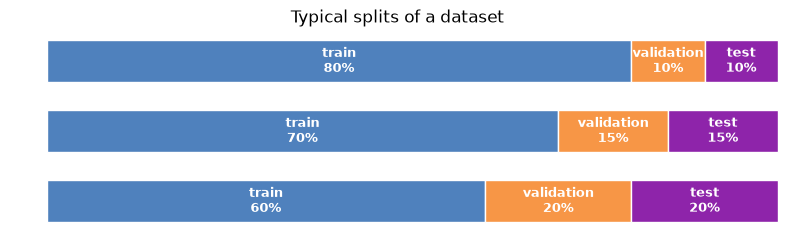

In [8]:
_fig, _ax = plt.subplots(figsize=(10, 2.6))
for _row, (_train, _validation, _test) in enumerate(((0.8, 0.1, 0.1), (0.7, 0.15, 0.15), (0.6, 0.2, 0.2))):
    draw_bar(_ax, [(f"train\n{_train:.0%}", _train, "#4f81bd"), (f"validation\n{_validation:.0%}", _validation, "#f79646"),
                   (f"test\n{_test:.0%}", _test, "#8e24aa")], -_row)
_ax.set_xlim(-0.05, 1.01)
_ax.axis("off")
_ax.set_title("Typical splits of a dataset")
plt.show()

## 6.2 Underfitting and overfitting

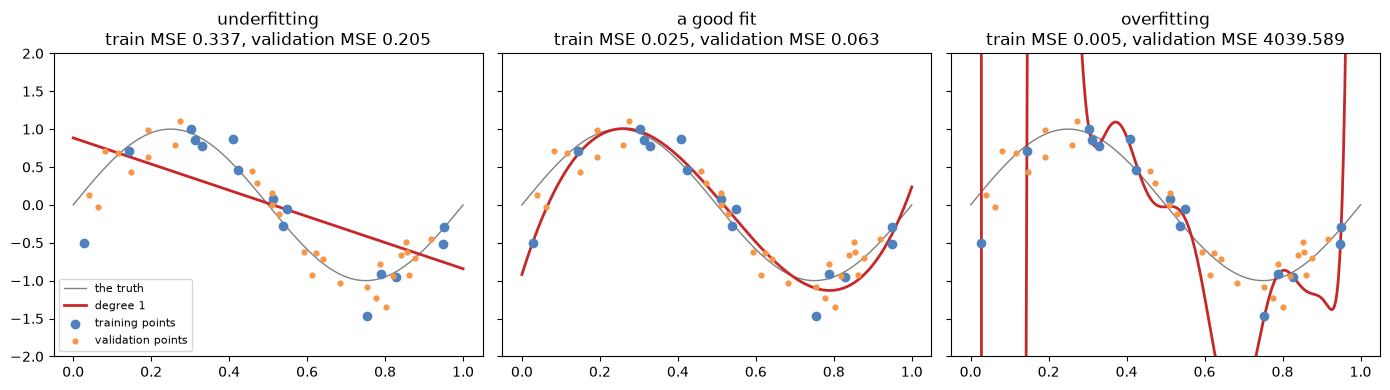

In [9]:
wave_x_train, wave_y_train, wave_x_val, wave_y_val = make_wave_split()
draw_degree_fits(wave_x_train, wave_y_train, wave_x_val, wave_y_val)

- **Underfitting**: the model is **too simple** - a line cannot follow a wave. It is bad on the training data
  **and** on the validation data. It has not learned the pattern.
- **A good fit**: close to the truth, and almost as good on the validation points as on the training points.
- **Overfitting**: the model is **too complex**. It passes close to **every** training
  point, including their noise. The training error is the smallest of the three, but between different training points it makes wild predictions - it **memorized** the training data instead of **learning the pattern**.

**The signs**: underfitting - high training error. Overfitting - low training error, but a much higher validation error.

Now the training and validation error for models with increasing complexity:

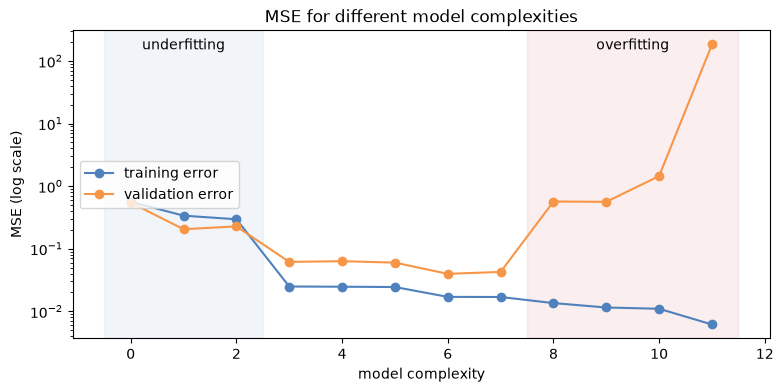

In [10]:
_degrees = range(12)
_train_errors, _val_errors = [], []
for _degree in _degrees:
    _model = Polynomial.fit(wave_x_train, wave_y_train, _degree)
    _train_errors.append(mean_squared_error(wave_y_train, _model(wave_x_train)))
    _val_errors.append(mean_squared_error(wave_y_val, _model(wave_x_val)))

_fig, _ax = plt.subplots(figsize=(9, 4))
_ax.plot(_degrees, _train_errors, "o-", color="#4f81bd", label="training error")
_ax.plot(_degrees, _val_errors, "o-", color="#f79646", label="validation error")
_ax.set_yscale("log")
_ax.set_xlabel("model complexity")
_ax.set_ylabel("MSE (log scale)")
_ax.axvspan(-0.5, 2.5, color="#4f81bd", alpha=0.08)
_ax.axvspan(7.5, 11.5, color="#c62828", alpha=0.08)
_ax.text(1, _ax.get_ylim()[1] * 0.5, "underfitting", ha="center")
_ax.text(9.5, _ax.get_ylim()[1] * 0.5, "overfitting", ha="center")
_ax.legend(loc="center left")
_ax.set_title("MSE for different model complexities")
plt.show()

This is the most important plot in machine learning:

- The **training error** always goes down as the model gets more complex - a more flexible model can always fit the
  training points better.
- The **validation error** first goes down (the model learns the pattern), then goes **up** (the model learns the
  noise). The best model is at the bottom of the validation curve.

So we choose the hyperparameters by the **validation** error, never by the training error.

## 6.3 The bias-variance tradeoff

Why does a too simple and a too complex model both fail? Imagine collecting a **new** training set many times and training the same kind of model on each one. Below are drawn 30 models with low complexity(a straight line) and 30 models with high complexity (polynomials with big degrees), each trained on
15 points with new random noise:

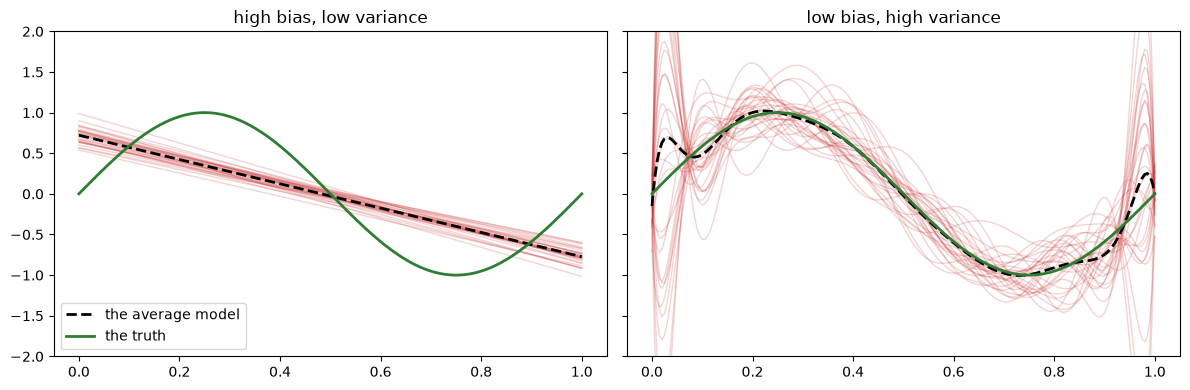

In [11]:
_rng = np.random.default_rng(7)
_grid = np.linspace(0, 1, 200)
_x = np.linspace(0, 1, 15)                                       # the same 15 positions every time
_fig, _axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for _ax, _degree, _verdict in zip(_axes, (1, 12), ("high bias, low variance", "low bias, high variance")):
    _curves = []
    for _ in range(30):
        _y = true_curve(_x) + _rng.normal(0, 0.25, len(_x))     # a new training set: new noise
        _curves.append(Polynomial.fit(_x, _y, _degree)(_grid))
        _ax.plot(_grid, _curves[-1], color="#c62828", alpha=0.2, lw=1)
    _ax.plot(_grid, np.mean(_curves, axis=0), color="black", lw=2, linestyle="--", label="the average model")
    _ax.plot(_grid, true_curve(_grid), color="#2e7d32", lw=2, label="the truth")
    _ax.set_ylim(-2, 2)
    _ax.set_title(f"{_verdict}")
_axes[0].legend(loc="lower left")
_fig.tight_layout()
plt.show()

- **Bias**: how far the model is from the truth - an error that comes from the model's
  **assumptions**. Every line is wrong in the same way, because a line cannot be a wave, however much data we give it.
  **High bias = underfitting.**
- **Variance**: how much the model **changes** when it is trained on a different sample of data. The degree-12 polynomials are close to the truth on average, but every single one is different - each polynomial follows the noise of its own 15 points. **High variance = overfitting.**

Making the model more complex lowers the bias but raises the variance, and having too simple of a model lowers the variance but raises the bias - this is the **bias-variance tradeoff**.
**The goal is to find the sweet spot in between** - in our example the polynomials of degree 3 to 7 have a similarly low validation error (the lowest is at degree 6), which is between the straight line (degree 1) that underfits and the degree 12 polynomial that overfits.

How to fight **overfitting** (high variance): **more training data, a simpler model, regularization**. Regularization is not covered in this lecture.

How to fight **underfitting** (high bias): **a more complex model, better features**.

## 6.4 Cross-validation

With a small dataset, one validation set is a problem. It takes data away from training (and we end up with less data than the model could use to train), and the validation error depends a lot on **which** points happened to end up in the validation set.

**k-fold cross-validation** uses all the data for both:

1. Split the training data into $k$ equal parts (**folds**), e.g. $k = 5$ or $k = 10$.
2. Train $k$ times: each time, one fold is the validation set, and the other $k - 1$ folds are the training set.
3. The cross-validation error is the **average** of the $k$ validation errors (for example, we average the accuracies of 93%, 90%, 91%, ..., 95% in 10 rounds - these are the accuracies of each fold).

Every example is used for validation exactly once, and for training $k - 1$ times. It costs $k$ trainings instead of one.
The test set is still kept aside for the very end.

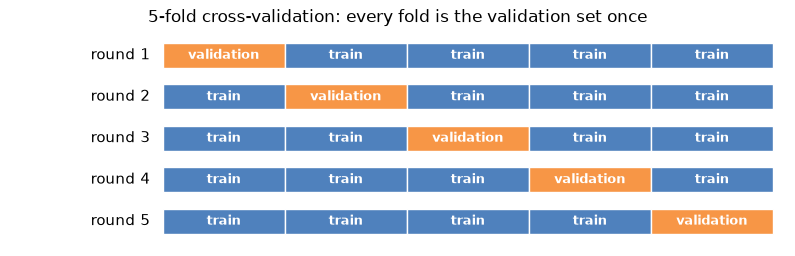

In [12]:
_fig, _ax = plt.subplots(figsize=(10, 2.8))
draw_k_fold(_ax, k=5)
_ax.set_title("5-fold cross-validation: every fold is the validation set once")
plt.show()

In [13]:
def cross_validation_error(x, y, degree, k=5):
    folds = np.array_split(np.random.default_rng(0).permutation(len(x)), k)
    errors = []
    for fold in folds:
        train = np.setdiff1d(np.arange(len(x)), fold)          # all the other folds
        model = Polynomial.fit(x[train], y[train], degree)
        errors.append(mean_squared_error(y[fold], model(x[fold])))
    return np.mean(errors)


_x, _y = make_wave(40, np.random.default_rng(2))
_cv_errors = {degree: cross_validation_error(_x, _y, degree) for degree in range(1, 11)}
for _degree, _error in _cv_errors.items():
    print(f"degree {_degree:>2}: 5-fold cross-validation MSE {_error:.3f}")
print("\nthe best degree:", min(_cv_errors, key=_cv_errors.get))

degree  1: 5-fold cross-validation MSE 0.275
degree  2: 5-fold cross-validation MSE 0.322
degree  3: 5-fold cross-validation MSE 0.100
degree  4: 5-fold cross-validation MSE 0.101
degree  5: 5-fold cross-validation MSE 0.122
degree  6: 5-fold cross-validation MSE 0.140
degree  7: 5-fold cross-validation MSE 0.201
degree  8: 5-fold cross-validation MSE 1.294
degree  9: 5-fold cross-validation MSE 0.420
degree 10: 5-fold cross-validation MSE 0.323

the best degree: 3


Cross-validation picks the degree of the polynomial (the hyperparameter) automatically. After choosing it, **we train one final model on all the training data, and evaluate it once on the test set**.

---

# 7. Logistic regression

## 7.1 From numbers to classes

Now the output is a **class**, not a number. For example, we could predict if a tumour is **dangerous** (1) or **not dangerous** (0), given its size.

Can we use linear regression with the labels 0 and 1, and say "class 1 if $\hat{y} > 0.5$"?

It works badly, because a line goes below 0 and above 1, and these values mean nothing. We
would rather have the model output a **probability**: a number between 0 and 1, "the tumour is dangerous with
probability 0.8".

**Logistic regression** takes the linear model and passes its output through the **sigmoid** (logistic) function:

$$z = w_0 + w_1 x_1 + \dots + w_n x_n \qquad \hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}}$$

- $z$ is exactly linear regression - any number from $-\infty$ to $+\infty$
- the sigmoid squeezes it into $(0, 1)$: very negative $z$ → close to 0, very positive $z$ → close to 1, $z = 0$ → 0.5
- $\hat{y}$ is read as **the probability of class 1**; we predict class 1 if $\hat{y} > 0.5$

So logistic regression **is** linear regression, extended to predict **probabilities**. It is used for
**classification** - the "regression" in the name only means that it computes a number (the probability).

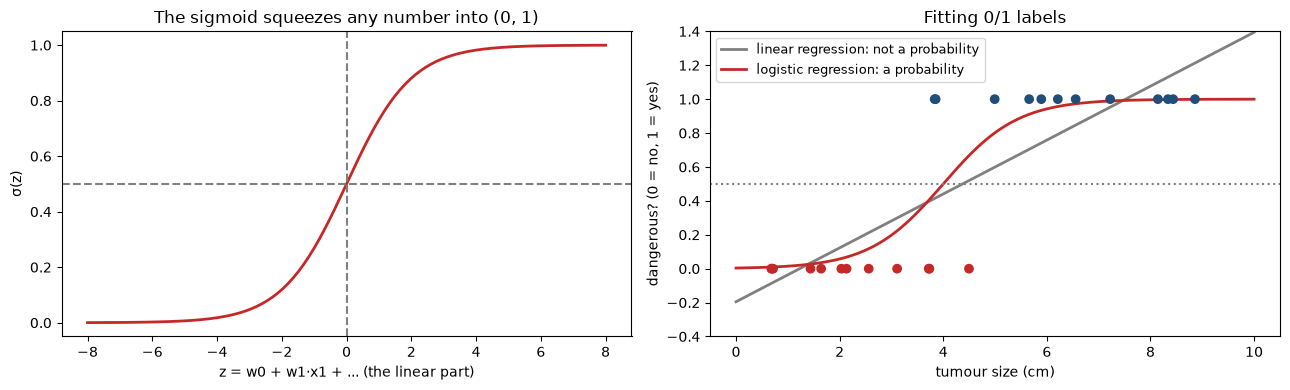

In [14]:
_rng = np.random.default_rng(5)
_size = np.r_[_rng.uniform(0.5, 4.5, 12), _rng.uniform(3.5, 9, 12)]
_label = np.r_[np.zeros(12), np.ones(12)]

_fig, (_left, _right) = plt.subplots(1, 2, figsize=(13, 4))
_z = np.linspace(-8, 8, 200)
_left.plot(_z, sigmoid(_z), color="#c62828", lw=2)
_left.axhline(0.5, color="gray", linestyle="--")
_left.axvline(0, color="gray", linestyle="--")
_left.set_xlabel("z = w0 + w1·x1 + ... (the linear part)")
_left.set_ylabel("σ(z)")
_left.set_title("The sigmoid squeezes any number into (0, 1)")

_grid = np.linspace(0, 10, 200)
_line = np.polyfit(_size, _label, 1)                       # linear regression on the 0/1 labels
_w0, _w1 = -5.6, 1.4                                         # a sigmoid with weights chosen by hand for this picture
_right.scatter(_size, _label, c=np.where(_label == 1, "#1f4e79", "#c62828"), zorder=3)
_right.plot(_grid, np.polyval(_line, _grid), color="gray", lw=2, label="linear regression: not a probability")
_right.plot(_grid, sigmoid(_w0 + _w1 * _grid), color="#c62828", lw=2, label="logistic regression: a probability")
_right.axhline(0.5, color="gray", linestyle=":")
_right.set_ylim(-0.4, 1.4)
_right.set_xlabel("tumour size (cm)")
_right.set_ylabel("dangerous? (0 = no, 1 = yes)")
_right.legend(loc="upper left", fontsize=9)
_right.set_title("Fitting 0/1 labels")
_fig.tight_layout()
plt.show()

The line (gray) goes below 0 and above 1. The sigmoid (red) stays between 0 and 1 - small tumours get a probability close to 0, big ones close to 1, and the ones in between are uncertain.

## 7.2 The loss for logistic regression - **cross-entropy**

For probabilities, the MSE is not a good loss. Logistic regression uses the **binary cross-entropy** (also called the **log loss**):

$$Loss = -\frac{1}{N} \sum_{j=1}^{N} \left[ y_j \log(\hat{y}_j) + (1 - y_j) \log(1 - \hat{y}_j) \right]$$

It looks complicated, but for each example only one of the two terms is active:

- if the true class is $y = 1$, the loss is $-\log(\hat{y})$: small if the model gave class 1 a high probability
- if the true class is $y = 0$, the loss is $-\log(1 - \hat{y})$: small if the model gave class 1 a low probability
- $-\log(p)$ takes values in $[0, +\infty)$ for $p \in (0, 1]$, so it makes sense for it to be a loss

A **confident wrong** answer is punished very hard: $-\log(0.01) \approx 4.6$, and $-\log(p) \to \infty$ as $p \to 0$.

## 7.3 Results of logistic regression

The data: points with 2 features, from two overlapping groups (class 0 red, class 1 blue). We split them 75% / 25% into
a training and a test set, scale the features (standardization, with the mean and standard deviation of the
**training** set only), and train with gradient descent.

weights: [5.08 3.51], bias: -0.50
cross-entropy: 0.693 at the start -> 0.136 after training
train accuracy: 95%
test accuracy:  100%


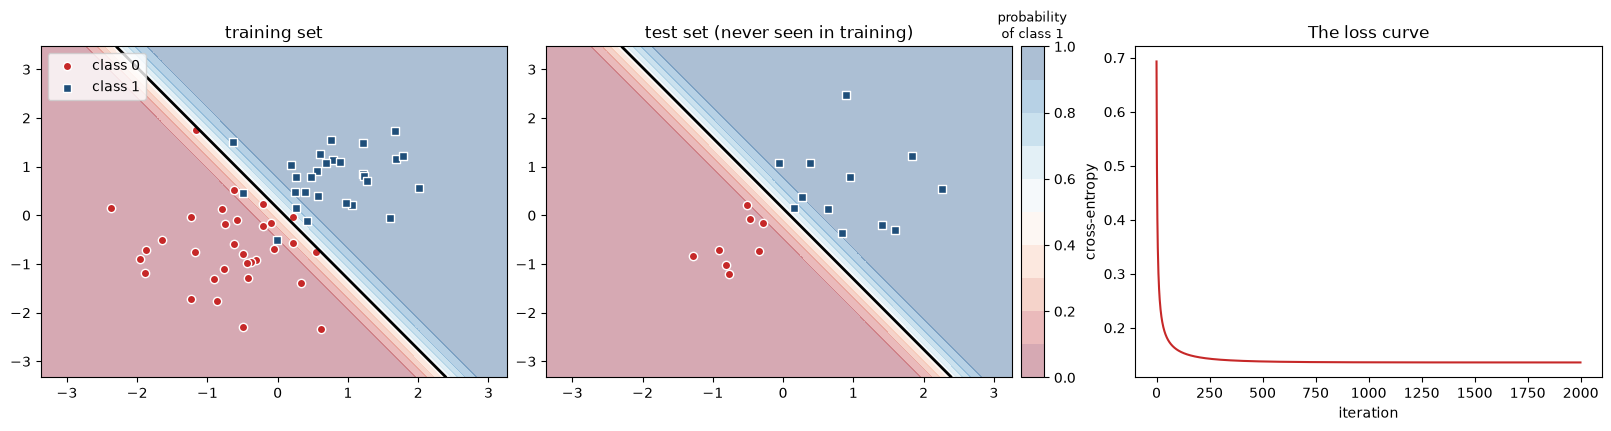

In [15]:
draw_logistic_regression()

- The background colour is the predicted **probability** of class 1: dark blue - surely class 1, dark red - surely class
  0, pale - unsure.
- The black line is where the probability is exactly 0.5 - the **decision boundary**. It is where $z = w_0 + w_1 x_1 +
  w_2 x_2 = 0$, which is the equation of a **straight line**. Logistic regression is a **linear classifier**.
- The two groups overlap, so a few points are on the wrong side - no straight line can separate them perfectly, and
  that is fine. The test accuracy is close to the training accuracy, so the model is not overfitting.

---

# 8. Summary

| Concept | In one sentence |
|---|---|
| **Machine learning** | the computer learns a rule (a model) from examples, instead of us programming the rule |
| **Supervised / unsupervised** | with labels (the right answers) / without labels (find structure, e.g. clusters) |
| **Regression / classification** | predict a number / predict a class |
| **Learnable parameters** | the numbers inside the model (weights, bias), found by training |
| **Hyperparameters** | the numbers we choose before training (learning rate, degree) |
| **Loss** | how wrong the model is: MSE for regression, cross-entropy for classification |
| **Gradient descent** | repeatedly step the parameters downhill on the loss; the learning rate is the step size |
| **Train / validation / test** | learn / choose hyperparameters / final estimate on unseen data |
| **Underfitting** | too simple, high bias: bad on training and on new data |
| **Overfitting** | too complex, high variance: good on training, bad on new data |
| **Cross-validation** | rotate the validation fold $k$ times and average - a reliable validation error from little data |
| **Linear regression** | $\hat{y} = w_0 + w_1 x_1 + \dots$, a model for **regression** |
| **Logistic regression** | $\hat{y} = \sigma(w_0 + w_1 x_1 + \dots)$, linear regression turned into a probability - a model for **classification** |